<a href="https://colab.research.google.com/github/s38250025-Alra/SequentialData_Sem3/blob/main/LSTM_Energy_Forecasting_Student_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Individual: Prediksi Konsumsi Listrik Gedung dengan LSTM

**Mata kuliah:** Sequential Data Analytics and Modeling (AID01) — S1 Artificial Intelligence, Universitas Bunda Mulia  
**Waktu:** 120 menit  
**Pengerjaan:** Individual

**Kasus:** Prediksi pemakaian listrik (`power_kw`) satu jam setelah pengamatan terakhir, menggunakan 36 data (6 jam) sebelumnya. Satu data dicatat setiap 10 menit.

**Aturan:** Isi bagian `TODO MAHASISWA` sendiri. Jalankan setiap eksperimen dan catat angka aktual pada tabel. Jangan mengarang hasil. Boleh menggunakan dokumentasi Python/TensorFlow, tetapi Anda harus bisa menjelaskan setiap baris yang Anda tulis.


## 1. Import library dan isi NIM

Ubah `nim_akhir` menjadi empat digit terakhir NIM Anda. Ini menghasilkan variasi data yang deterministik untuk setiap mahasiswa.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

nim_akhir = 25  # TODO MAHASISWA: ganti dengan 4 digit terakhir NIM
seed = int(nim_akhir)
np.random.seed(seed)
tf.keras.utils.set_random_seed(seed)

print("NIM akhir:", nim_akhir)

NIM akhir: 25


## 2. Baca dataset

Upload file `Smart_Building_Energy_90_Days.csv` ke folder **Files** Google Colab. Gunakan path `/content/Smart_Building_Energy_90_Days.csv`.

In [15]:
file_csv = '/content/Smart_Building_Energy_90_Days.csv'
data = pd.read_csv(file_csv)
data['timestamp'] = pd.to_datetime(data['timestamp'])
data = data.sort_values('timestamp').reset_index(drop=True)

print('Jumlah baris:', len(data))
print(data.head())
print('Data kosong:', data.isna().sum().sum())

Jumlah baris: 12960
            timestamp  power_kw  temperature_c  occupancy  is_weekend
0 2026-01-01 00:00:00     53.75          26.08         37           0
1 2026-01-01 00:10:00     53.22          26.78          7           0
2 2026-01-01 00:20:00     50.29          25.85         41           0
3 2026-01-01 00:30:00     52.57          25.40         38           0
4 2026-01-01 00:40:00     45.56          25.79          8           0
Data kosong: 0


## 3. Pilih konsumsi listrik dan buat versi data sesuai NIM

Praktikum ini memakai **satu fitur saja**, yaitu `power_kw`. Agar hasil antar mahasiswa tidak identik, tambahkan variasi kecil yang ditentukan NIM. Variasi ini tidak dibuat acak ulang setiap training.

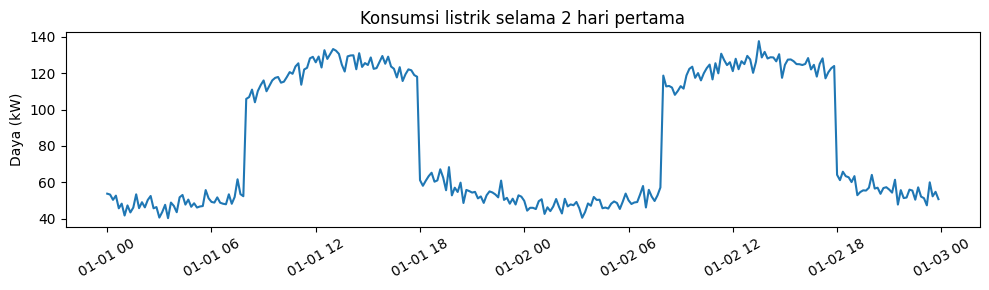

In [16]:
daya_asli = data['power_kw'].to_numpy(dtype='float32')

# Variasi NIM kecil, berulang sepanjang hari; hasil selalu sama untuk NIM yang sama
waktu = np.arange(len(daya_asli), dtype='float32')
variasi = (seed % 19) * 0.12 * np.sin(2 * np.pi * waktu / 144)
daya = daya_asli + variasi

plt.figure(figsize=(10, 3))
plt.plot(data['timestamp'].iloc[:288], daya[:288])
plt.title('Konsumsi listrik selama 2 hari pertama')
plt.ylabel('Daya (kW)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Normalisasi data

Hitung nilai rata-rata dan simpangan baku dari 70% awal data saja (data training). Jangan mengambil informasi statistik dari masa depan.

In [17]:
batas_awal = int(len(daya) * 0.70)
rata = daya[:batas_awal].mean()
std = daya[:batas_awal].std()

if std == 0:
    std = 1.0

daya_normal = (daya - rata) / std
print('Rata-rata training:', round(float(rata), 2), 'kW')
print('Standar deviasi training:', round(float(std), 2), 'kW')

Rata-rata training: 73.21 kW
Standar deviasi training: 31.88 kW


## 5. Ubah deret waktu menjadi input dan target

**Input:** 36 angka terakhir (6 jam). **Target:** angka 6 langkah setelah input terakhir (1 jam). Lengkapi dua baris `TODO MAHASISWA`.

In [18]:
window = 36
jarak = 6
X = []
y = []

for i in range(len(daya_normal) - window - jarak + 1):
    # TODO MAHASISWA 1: ambil 36 angka dari indeks i
    input_data = daya_normal[i:i + window]
    # TODO MAHASISWA 2: target pada indeks i + window + jarak - 1
    target = daya_normal[i + window + jarak - 1]
    X.append(input_data)
    y.append(target)

X = np.array(X).reshape(-1, window, 1)
y = np.array(y)
print('X:', X.shape, 'y:', y.shape)

X: (12919, 36, 1) y: (12919,)


## 6. Bagi data sesuai waktu

70% awal untuk training, 15% berikutnya validation, dan 15% terakhir testing. **Tidak diacak.** Data test tidak digunakan untuk memilih hyperparameter.

In [19]:
n = len(X)
a = int(n * 0.70)
b = int(n * 0.85)
X_train, y_train = X[:a], y[:a]
X_val, y_val = X[a:b], y[a:b]
X_test, y_test = X[b:], y[b:]

print('Train:', len(X_train))
print('Validation:', len(X_val))
print('Test:', len(X_test))

Train: 9043
Validation: 1938
Test: 1938


## 7. Fungsi untuk membuat dan melatih LSTM

Model sederhana: `Input → LSTM → Dense(1)`. Untuk membandingkan eksperimen secara adil, semua konfigurasi memakai learning rate dan batch size yang sama.

In [20]:
def buat_model(jumlah_neuron, panjang_window):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(panjang_window, 1)),
        tf.keras.layers.LSTM(jumlah_neuron),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer='adam', loss='mae')
    return model

print('Model siap dibuat.')

Model siap dibuat.


## 8. Jalankan empat eksperimen

Ubah **satu parameter** terhadap baseline pada E2–E4. E1: 16 neuron, 3 epoch, window 36. E2: 32 neuron. E3: 8 epoch. E4: window 12.

Untuk E4, data window dibuat ulang sesuai panjangnya; pemisahan tetap kronologis. Tabel hanya menggunakan **validation MAE (kW)** untuk menentukan konfigurasi terbaik.

In [21]:
def buat_window(angka, panjang_window, jarak=6):
    X_baru = []
    y_baru = []
    for i in range(len(angka) - panjang_window - jarak + 1):
        X_baru.append(angka[i:i + panjang_window])
        y_baru.append(angka[i + panjang_window + jarak - 1])
    return np.array(X_baru).reshape(-1, panjang_window, 1), np.array(y_baru)

# Daftar percobaan. Jangan ubah konfigurasi selain yang diminta.
percobaan = [
    ('E1', 16, 3, 36),
    ('E2', 32, 3, 36),
    ('E3', 16, 8, 36),
    ('E4', 16, 3, 12),
]

hasil_semua = []
model_semua = {}
data_semua = {}

for nama, neuron, epoch, panjang in percobaan:
    tf.keras.utils.set_random_seed(seed)
    XX, yy = buat_window(daya_normal, panjang)
    n = len(XX)
    a = int(n * 0.70)
    b = int(n * 0.85)
    xx_train, yy_train = XX[:a], yy[:a]
    xx_val, yy_val = XX[a:b], yy[a:b]
    xx_test, yy_test = XX[b:], yy[b:]

    model = buat_model(neuron, panjang)
    model.fit(xx_train, yy_train, validation_data=(xx_val, yy_val),
              epochs=epoch, batch_size=128, shuffle=False, verbose=0)
    pred_val = model.predict(xx_val, verbose=0).flatten()
    mae_val = np.mean(np.abs(yy_val - pred_val)) * std

    hasil_semua.append([nama, neuron, epoch, panjang, round(float(mae_val), 3)])
    model_semua[nama] = model
    data_semua[nama] = (xx_test, yy_test)
    print(nama, '| validation MAE =', round(float(mae_val), 3), 'kW')

hasil_df = pd.DataFrame(hasil_semua, columns=['Eksperimen', 'Neuron', 'Epoch', 'Window', 'Validation MAE (kW)'])
print(hasil_df.to_string(index=False))

E1 | validation MAE = 7.485 kW
E2 | validation MAE = 7.484 kW
E3 | validation MAE = 6.656 kW
E4 | validation MAE = 8.115 kW
Eksperimen  Neuron  Epoch  Window  Validation MAE (kW)
        E1      16      3      36                7.485
        E2      32      3      36                7.484
        E3      16      8      36                6.656
        E4      16      3      12                8.115


## 9. Pilih model terbaik dan uji sekali pada test set

Pilih MAE validation paling kecil. Setelah itu hitung **test MAE (kW)** dan bandingkan dengan baseline naïf yang memakai konsumsi listrik terakhir sebagai prediksi satu jam ke depan.

In [22]:
terbaik = hasil_df.loc[hasil_df['Validation MAE (kW)'].idxmin(), 'Eksperimen']
model_terbaik = model_semua[terbaik]
XX_test, yy_test = data_semua[terbaik]

pred_normal = model_terbaik.predict(XX_test, verbose=0).flatten()
pred_kw = pred_normal * std + rata
aktual_kw = yy_test * std + rata
baseline_kw = XX_test[:, -1, 0] * std + rata

# TODO MAHASISWA 3: hitung rata-rata nilai mutlak selisih aktual dan prediksi
mae_lstm = np.mean(np.abs(aktual_kw - pred_kw))
# TODO MAHASISWA 4: hitung MAE untuk baseline
mae_baseline = np.mean(np.abs(aktual_kw - baseline_kw))

print('Model terbaik:', terbaik)
print('Test MAE LSTM:', round(float(mae_lstm), 3), 'kW')
print('Test MAE baseline:', round(float(mae_baseline), 3), 'kW')

Model terbaik: E3
Test MAE LSTM: 6.563 kW
Test MAE baseline: 7.538 kW


## 10. Grafik hasil dan simpan tabel

Gunakan grafik untuk membahas apakah LSTM menangkap pola perubahan daya. **Grafik adalah hasil eksekusi, bukan gambar buatan AI.**

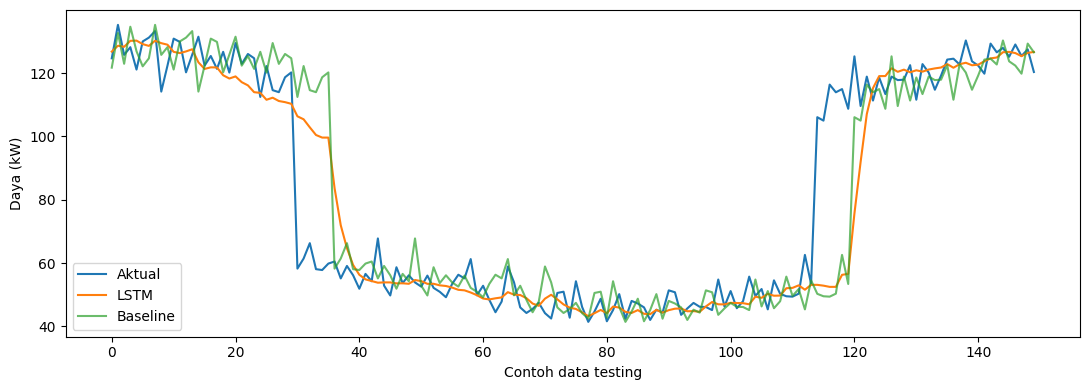

Tabel tersimpan: hasil_eksperimen.csv


In [23]:
plt.figure(figsize=(11, 4))
plt.plot(aktual_kw[:150], label='Aktual')
plt.plot(pred_kw[:150], label='LSTM')
plt.plot(baseline_kw[:150], label='Baseline', alpha=0.7)
plt.xlabel('Contoh data testing')
plt.ylabel('Daya (kW)')
plt.legend()
plt.tight_layout()
plt.show()

hasil_df.to_csv('hasil_eksperimen.csv', index=False)
print('Tabel tersimpan: hasil_eksperimen.csv')

## 11. Pertanyaan untuk slide laporan

1. Apa perbedaan input 36 dan target 6 langkah sesudahnya? Input 36 itu data konsumsi listrik selama 6 jam sebelumnya yang digunakan sebagai bahan untuk prediksi. Sedangkan target 6 langkah sesudahnya adalah data yang ingin diprediksi, yaitu konsumsi listrik 1 jam setelah data input terakhir.

2. Mana konfigurasi dengan validation MAE terkecil? Sertakan angkanya.! Konfigurasi E3, dengan 16 neuron, 8 epoch, dan window 36. Nilai Validation MAE sebesar 6.658 kW.

3. Apakah 32 neuron lebih baik daripada 16 neuron? Tunjukkan bukti.! Sedikit lebih baik pada perbandingan E1 dan E2. MAE 32 neuron sebesar 7.484 kW, sedangkan 16 neuron sebesar 7.485 kW. Selisihnya sangat kecil. 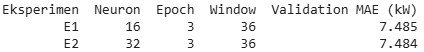

4. Apakah penambahan epoch memperbaiki hasil? Iya. Pada E1 dan E3, saat epoch ditambah dari 3 menjadi 8, MAE turun dari 7.485 menjadi 6.658 kW.

5. Apakah model terbaik mengalahkan baseline pada test set? Jelaskan menggunakan MAE dalam kW.! Iya. MAE LSTM sebesar 6.563 kW, sedangkan baseline sebesar 7.538 kW. Artinya, LSTM menghasilkan prediksi yang lebih akurat.

6. Mengapa data deret waktu tidak boleh dibagi secara acak? Karena urutan waktu harus tetap terjaga. Jika dibagi secara acak, data masa depan bisa tercampur dengan data masa lalu sehingga hasil pengujian menjadi tidak akurat.

**Dikumpulkan:** notebook `.ipynb` dengan output, `hasil_eksperimen.csv`, dan presentasi 5 slide. Semua sebelum akhir kelas. Cantumkan pemanfaatan AI apabila ada.